# Adversarial Search: Solving Tic-Tac-Toe with Minimax Search and Alpha-Beta Pruning

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. __Optimal Decisions:__ Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* __minimax search,__
* __minimax search with alpha-beta pruning,__ and
* __move ordering__. 

The search time (number if nodes explored) could be further improved by 
* __heuristic alpha-beta tree search__ (cut off search and use heuristic evaluation function to approximate utility), 
* __forward pruning__ (prune moves that appear poor), and
* __table lookups__ (for openings and end game).

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Recursive DFS algorithm for Minimax Search

See AIMA page 150. 

Note that the minimax search algorithm is very similar to AND-OR search where max does OR and min is represented by AND nodes.

In [3]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def minimax_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value(board, player)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
 
    return { "move": move, "value": value}

def max_value(state, player):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("max in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, return move with the largest value
    for a in actions(state):
        v2, a2 = min_value(result(state, player, a), player)
        if v2 > v:
            v, move = v2, a
    
    if DEBUG >= 2: print("max out: " + str(state) + str([v, move]) ) 
    return v, move

def min_value(state, player):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("min in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value(result(state, other(player), a), player)
        if v2 < v:
            v, move = v2, a
    
    if DEBUG >= 2: print("min out: " + str(state) + str([v, move]) ) 
    return v, move

## Some Tests

### x is about to win (choose 8)

Board:


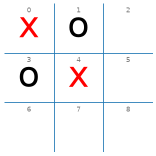


Number of nodes searched: 190


{'move': 2, 'value': 1}

CPU times: user 11.7 ms, sys: 0 ns, total: 11.7 ms
Wall time: 11.7 ms


In [4]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Nhận xét.** Minimax xét **190 nút** rồi chọn ô **2** với giá trị **+1** (x chắc chắn thắng). Một **nút** là một thế cờ mà thuật toán phải xem qua. **Minimax** là: thử từng nước đi của mình, giả sử đối thủ luôn đáp trả cách tốt nhất *cho họ*, rồi chọn nước cho mình điểm cao nhất.

Máy không chọn ô 8 (thắng ngay) vì ô 2 cũng dẫn tới thắng chắc, và thuật toán chỉ đổi nước khi gặp nước *tốt hơn hẳn*, nên nó giữ nước tốt đầu tiên gặp (ô 2 được xét trước ô 8). Đúng như ghi chú ngay bên dưới của notebook gốc: cách tìm này không chọn đường thắng ngắn nhất.

**Note:** DFS does not pick the the shortest path to a win! Discounting the utility can help.

### x can draw if it chooses 7

Board:


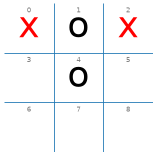


Number of nodes searched: 206


{'move': 7, 'value': 0}

CPU times: user 9.62 ms, sys: 40 μs, total: 9.66 ms
Wall time: 9.55 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Nhận xét.** Minimax xét **206 nút**, chọn ô **7**, giá trị **0** (hòa). Giá trị 0 nghĩa là nếu cả hai chơi đúng thì kết quả là hòa. Ô 7 là nước **duy nhất** giữ được hòa cho x (Bảng 1 ở cuối notebook kiểm tra lại điều này).

### A bad situation


Board:


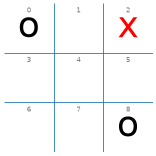


Number of nodes searched: 941


{'move': 1, 'value': -1}

CPU times: user 33.4 ms, sys: 48 μs, total: 33.5 ms
Wall time: 34.5 ms


In [6]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Nhận xét.** Minimax xét **941 nút**, chọn ô **1**, giá trị **-1**. Giá trị -1 nghĩa là nếu o chơi đúng thì x thua dù đi ô nào, nên cả 6 nước còn lại đều có giá trị -1 và thuật toán giữ nước đầu tiên (ô 1). Số nút lớn hơn hai ví dụ trước vì ở đây còn 6 ô trống (hai ví dụ trước còn 5 ô), nên cây các nước đi lớn hơn.

### Empty board

Board:


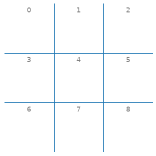

Number of nodes searched: 549946


{'move': 0, 'value': 0}

CPU times: user 18.7 s, sys: 1.65 ms, total: 18.7 s
Wall time: 18.8 s


In [7]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(minimax_search(board))

**Nhận xét.** Minimax xét **549,946 nút**: đây là kích thước của **toàn bộ** cây trò chơi (như ghi chú ngay bên dưới). Giá trị là **0** (hòa), và máy chọn ô 0 vì cả 9 ô đều dẫn tới hòa nên nó giữ ô đầu tiên. So với ba ví dụ trước (chỉ vài trăm nút) thì rất chậm, thời gian chạy tính bằng chục giây (xem dòng `Wall time` ở trên). Cần một cách bỏ bớt những nhánh không cần xét: đó là Alpha-Beta ở phần sau.

__Note:__ Starting with an empty board searched the complete game tree and takes a while. The number of nodes above is the actual size of the complete game tree. A table with know 'openings' (e.g., place x in a corner, o chooses the center, etc.) would be helpful to speed things up.

# Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning

See AIMA page 154. 

Adds alpha-beta pruning to minimax search. Alpha and beta are used to maintain bounds on the minimax value of a node in the form `[alpha, beta]`. alpha means that the value is at least that high and beta means that the actual value is at most that high. Subtrees below a node that are worse than the currently known bound do not need to be further explored and can be pruned. Max uses alpha and Min uses beta for pruning.

The implementation is for player 'x' returns a the optimal next move.

In [8]:
# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value_ab(board, player, -math.inf, +math.inf)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
    
    return { "move": move, "value": value }

def max_value_ab(state, player, alpha, beta):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
       
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"max: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtracking.")
        return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta)
        if DEBUG >= 2: print(f"max: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta:
            if DEBUG >= 2: print(f"     v>=beta ({v}>={beta}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"min: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtacking.")
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta)
        if DEBUG >= 2: print(f"min: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: 
            if DEBUG >= 2: print(f"     v<=alpha ({v}<={alpha}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


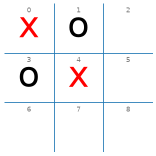


max: ['x', 'o', ' ', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] [alpha,beta]=[-inf,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'x', ' ', ' '] [alpha,beta]=[-inf,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '] (backtracked) [alpha,beta]=[-inf,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] [alpha,beta]=[1,inf] v=None
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] [alpha,beta]=[1,inf] v=None
min: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', 'x'] [alpha,beta]=[1,inf] v=1
     found terminal state. backtacking.
max: ['x', 'o', 'x', 'o', 'x', 'o', 'o', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
min: ['x', 'o', 'x', 'o', 'x', 'o', ' ', 'x', ' '] (backtracked) [alpha,beta]=[1,inf] v=1
     v<=alpha (1<=1): pruning remaining subtree (actions). backtracking.
max: ['x', 'o'

{'move': 2, 'value': 1}

CPU times: user 3.78 ms, sys: 2 μs, total: 3.78 ms
Wall time: 3.66 ms


In [9]:
DEBUG = 2 # show more debugging info

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

**Nhận xét.** Ô này in rất nhiều dòng vì `DEBUG = 2` (ô gốc của thầy, mình giữ nguyên). Kết quả nằm ở cuối: nước **2**, giá trị **+1**, **61 nút** (Minimax cần 190 nút cho cùng thế cờ). Kết quả giống hệt Minimax nhưng ít nút hơn nhiều.

**Alpha-Beta** là Minimax có thêm một mẹo: máy nhớ "điểm tốt nhất mình đã chắc chắn có được". Khi xét một nhánh mà thấy đối thủ có cách đáp trả làm mình tệ hơn mức đó thì máy bỏ luôn cả nhánh, không xét tiếp. Việc bỏ nhánh này gọi là **cắt tỉa** (các dòng `pruning` ở trên).

The code does not pick the the shortest path to a win! Discounting could help.

### x can draw if it chooses 7

Board:


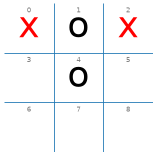


Number of nodes searched: 101


{'move': 7, 'value': 0}

CPU times: user 4.12 ms, sys: 1 μs, total: 4.12 ms
Wall time: 4.02 ms


In [10]:
DEBUG = 1

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

**Nhận xét.** Alpha-Beta xét **101 nút** (Minimax: 206), vẫn chọn ô **7** với giá trị **0**. Cùng kết quả, cắt được khoảng một nửa số nút.

### o is about to win no matter what x does


Board:


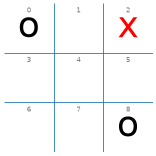


Number of nodes searched: 238


{'move': 1, 'value': -1}

CPU times: user 8.45 ms, sys: 2 μs, total: 8.45 ms
Wall time: 8.32 ms


In [11]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

**Nhận xét.** Alpha-Beta xét **238 nút** (Minimax: 941), vẫn chọn ô **1** với giá trị **-1**. Kết quả giống Minimax, số nút còn khoảng một phần tư.

### Empty board: Only a draw an be guaranteed

Board:


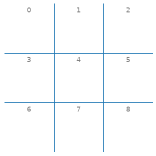

Number of nodes searched: 18297


{'move': 0, 'value': 0}

CPU times: user 588 ms, sys: 6 μs, total: 588 ms
Wall time: 588 ms


In [12]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

**Nhận xét.** Alpha-Beta xét **18,297 nút** (Minimax: 549,946), tức là giảm khoảng **30 lần**; thời gian chạy cũng giảm từ chục giây xuống dưới 1 giây (so hai dòng `Wall time`). Vẫn chọn ô **0** với giá trị **0** (hòa), giống Minimax.

**Note:** Alpha-Beta search expands fewer nodes and is **much faster** than minimax search. 

## Move ordering

Smart move reordering can make alpha-beta pruning more effective. I think the center `[4]` and corners `[0, 2, 6, 8]` are good. I implement move reordering in the `actions()`.

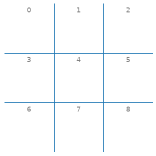

[4, 8, 6, 2, 0, 7, 5, 3, 1]

In [13]:
import numpy as np

def actions(board):
    """return possible actions as a vector ot indices"""
    actions = np.where(np.array(board) == ' ')[0].tolist()

    priority = [1,0,1,
                0,2,0,
                1,0,1]
    priority = [priority[i] for i in actions]
    
    actions =[a for _,a in sorted(zip(priority,actions), reverse=True)]
    
    return actions

board = empty_board()   
show_board(board)
actions(board)

### Empty board: Only a draw an be guaranteed

Board:


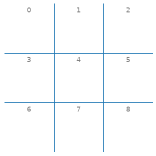

Number of nodes searched: 7275


{'move': 4, 'value': 0}

CPU times: user 277 ms, sys: 3 μs, total: 277 ms
Wall time: 278 ms


In [14]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

**Nhận xét.** Sau khi ưu tiên ô giữa rồi tới các góc, Alpha-Beta chỉ xét **7,275 nút** (trước đó là 18,297), còn khoảng 40%. Nước đi đổi từ ô 0 sang **ô 4** (ô giữa) nhưng giá trị vẫn là **0** (hòa): hai nước này tốt ngang nhau, chỉ khác thứ tự được xét. Bảng 2 ở cuối notebook so sánh trước / sau cho cả 4 trạng thái.

__Note:__ Compare to the number of nodes searched without move reordering (right above).

## Experiments


### Minimax with Alpha-Beta Pruning vs. Random

In [15]:
# Đặt seed để kết quả ván đấu với Random chạy lại vẫn ra như cũ (seed của phần Thiện).
np.random.seed(20261109)

In [16]:
DEBUG = 0

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, player)["move"]

print("alpha-beta vs. random:")
%time display(play(alpha_beta_player, random_player))

print()
print("random vs. alpha-beta")
%time display(play(random_player, alpha_beta_player))

alpha-beta vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: user 27.5 s, sys: 4.96 ms, total: 27.5 s
Wall time: 27.5 s

random vs. alpha-beta


{'x': 0, 'o': 89, 'd': 11}

CPU times: user 6.66 s, sys: 7 μs, total: 6.66 s
Wall time: 6.67 s


**Nhận xét.** Đã đặt seed `20261109` ngay trước ô này nên chạy lại vẫn ra như cũ; ô này dùng thứ tự nước đi đã sắp xếp. Trong 100 ván, Alpha-Beta đi trước (x) thắng **98**, hòa **2**, thua **0**. Khi đi sau (o) thắng **89**, hòa **11**, thua **0**. Alpha-Beta **không thua ván nào**, vì nó luôn chọn nước tối ưu và trên bàn 3×3 chơi đúng thì không thể thua. Vẫn có ván hòa vì Random đôi khi vô tình đi đúng, khi đó hai bên cùng chơi đúng và kết quả là hòa. Đi sau thì hòa nhiều hơn vì người đi trước có lợi thế. Ô đi trước chạy lâu hơn (khoảng 28 giây so với khoảng 7 giây), vì mỗi ván máy phải tìm trên bàn trống, còn khi đi sau thì bàn đã có 1 quân của Random nên cây nhỏ hơn.

**Note on runtime:** Compared to AND-OR Search, Minimax search is slower, because AND-OR Search terminates once it finds the first subtree that has only goal nodes, buy Minimax search traverses the whole tree (minus what is pruned if alpha-beta pruning is used). 

Also, I was lazy and recreate the search tree every time the agent is asked for a move. The agent could create the tree with the Minimax values once and then use it to decide on actions. A problem could be that the tree may be too large to store. 

## Bài 3 — Bảng so sánh Minimax và Alpha-Beta

Phần này gom các thí nghiệm ở trên thành bảng để so sánh trực tiếp (yêu cầu của Bài 3). Cách làm:

* Chạy **cùng một tập 4 trạng thái** (x sắp thắng, x cần đi 7 để hòa, tình huống bất lợi, bàn trống) cho cả `minimax_search` và `alpha_beta_search`, và ghi lại nước đi, giá trị, số nút và thời gian.
* Kiểm tra bằng `assert` rằng Alpha-Beta **không làm thay đổi quyết định tối ưu**.
* So sánh số nút **trước và sau** khi đổi thứ tự nước đi (Move ordering).

Số nút là con số cố định, chạy lại ở máy nào cũng ra như nhau. **Thời gian đo trên máy của Thiện, máy khác sẽ khác.**

In [17]:
import time
import pandas as pd

# Hai phiên bản thứ tự nước đi:
#  - actions_default: hàm gốc trong tictactoe.py (ô 0, 1, 2, ... theo thứ tự)
#  - actions_ordered: bản đã sắp xếp ở ô "Move ordering" phía trên (giữa, rồi góc)
from tictactoe import actions as actions_default
actions_ordered = actions


def run_search(search, board, order = "default"):
    """chạy một thuật toán (minimax_search hoặc alpha_beta_search) và trả về nước đi, giá trị, số nút, thời gian.
    order là "default" hoặc "ordered" (thứ tự nước đi). Hàm trả actions và DEBUG về như cũ khi xong."""
    global actions, DEBUG
    old_actions, old_debug = actions, DEBUG
    actions = actions_default if order == "default" else actions_ordered
    DEBUG = 0                                        # không in gì
    try:
        start = time.perf_counter()
        info = search(board)
        time_ms = (time.perf_counter() - start) * 1000
        nodes = COUNT                                # đọc COUNT ngay sau khi chạy
    finally:
        actions, DEBUG = old_actions, old_debug
    return {"move": info["move"], "value": info["value"], "nodes": nodes, "time_ms": time_ms}


def board_with(x = (), o = ()):
    """tạo bàn cờ với các ô của x và o."""
    board = empty_board()
    for i in x: board[i] = 'x'
    for i in o: board[i] = 'o'
    return board


# Bốn trạng thái giống hệt các ô thử nghiệm gốc ở trên
test_states = {
    "x sắp thắng":        board_with(x = [0, 4], o = [1, 3]),
    "x cần đi 7 để hòa":  board_with(x = [0, 2], o = [1, 4]),
    "tình huống bất lợi": board_with(x = [2],    o = [0, 8]),
    "bàn trống":          board_with(),
}
searches = {"Minimax": minimax_search, "Alpha-Beta": alpha_beta_search}

### Bảng 1 — Minimax và Alpha-Beta trên cùng trạng thái (thứ tự nước đi mặc định)

Cột "Giá trị" nhìn từ phía x: `+1` x thắng, `0` hòa, `-1` x thua. Bảng thứ hai kiểm tra Alpha-Beta có làm đổi quyết định tối ưu hay không. "Các nước tối ưu" được tính bằng cách thử từng nước hợp lệ rồi dùng lại hàm `min_value` có sẵn của Minimax để lấy giá trị, sau đó lấy các nước có giá trị lớn nhất.

In [18]:
# Bảng 1: cùng trạng thái, thứ tự nước đi mặc định
results_default = {}
rows = []
for state_name, board in test_states.items():
    for algo_name, search in searches.items():
        r = run_search(search, board, "default")
        results_default[(state_name, algo_name)] = r
        rows.append({"Trạng thái": state_name, "Thuật toán": algo_name, "Nước đi": r["move"],
                     "Giá trị": r["value"], "Số nút": r["nodes"], "Thời gian (ms)": round(r["time_ms"], 1)})

table1 = pd.DataFrame(rows)
display(table1)

,Trạng thái,Thuật toán,Nước đi,Giá trị,Số nút,Thời gian (ms)
0,x sắp thắng,Minimax,2,1,190,6.4
1,x sắp thắng,Alpha-Beta,2,1,61,2.0
2,x cần đi 7 để hòa,Minimax,7,0,206,6.7
3,x cần đi 7 để hòa,Alpha-Beta,7,0,101,3.3
4,tình huống bất lợi,Minimax,1,-1,941,29.7
5,tình huống bất lợi,Alpha-Beta,1,-1,238,7.8
6,bàn trống,Minimax,0,0,549946,17436.2
7,bàn trống,Alpha-Beta,0,0,18297,601.2


In [19]:
# Kiểm tra Alpha-Beta không đổi quyết định tối ưu.
# Các nước tối ưu: thử từng nước hợp lệ a, dùng min_value có sẵn để lấy giá trị, lấy các nước có giá trị lớn nhất.
DEBUG = 0
rows = []
for state_name, board in test_states.items():
    mm = results_default[(state_name, "Minimax")]
    ab = results_default[(state_name, "Alpha-Beta")]

    move_values = {a: min_value(result(board, 'x', a), 'x')[0] for a in actions_default(board)}
    best_value = max(move_values.values())
    optimal_moves = [a for a, v in move_values.items() if v == best_value]

    assert mm["value"] == ab["value"] == best_value, "Alpha-Beta đổi giá trị Minimax!"
    assert ab["move"] in optimal_moves, "Nước của Alpha-Beta không tối ưu!"

    rows.append({"Trạng thái": state_name, "Nước Minimax": mm["move"], "Nước Alpha-Beta": ab["move"],
                 "Cùng giá trị?": mm["value"] == ab["value"],
                 "Các nước tối ưu": str(optimal_moves) if len(optimal_moves) < 9 else "cả 9 ô (đều hòa)",
                 "Nước Alpha-Beta có tối ưu không?": ab["move"] in optimal_moves})

table1b = pd.DataFrame(rows)
display(table1b)
print("Tất cả kiểm tra assert đều qua.")

,Trạng thái,Nước Minimax,Nước Alpha-Beta,Cùng giá trị?,Các nước tối ưu,Nước Alpha-Beta có tối ưu không?
0,x sắp thắng,2,2,True,"[2, 6, 8]",True
1,x cần đi 7 để hòa,7,7,True,[7],True
2,tình huống bất lợi,1,1,True,"[1, 3, 4, 5, 6, 7]",True
3,bàn trống,0,0,True,cả 9 ô (đều hòa),True


Tất cả kiểm tra assert đều qua.


**Nhận xét Bảng 1.**

* Alpha-Beta luôn ra **cùng giá trị** với Minimax (+1, 0, -1, 0) và ở bốn trạng thái này cũng **cùng nước đi**, nhưng xét ít nút hơn hẳn: 190 → 61, 206 → 101, 941 → 238, và bàn trống 549,946 → 18,297 (giảm khoảng 30 lần; thời gian giảm từ chục giây xuống dưới 1 giây).
* Các `assert` đều qua: giá trị hai thuật toán bằng nhau và nước của Alpha-Beta nằm trong nhóm nước tối ưu. Vậy Alpha-Beta không làm thay đổi quyết định tối ưu.
* "x sắp thắng": máy chọn ô **2** chứ không chọn ô 8 thắng ngay, vì ô 2, 6 và 8 đều thắng chắc (các nước tối ưu là `[2, 6, 8]`) và thuật toán giữ nước tốt **đầu tiên** nó gặp. Notebook gốc cũng ghi chú điều này.
* "Tình huống bất lợi": cả 6 nước còn lại đều thua nếu o chơi đúng, nên nước nào cũng có giá trị -1 và đều "tối ưu"; máy giữ nước đầu tiên (ô 1).
* "x cần đi 7 để hòa": ô 7 là nước **duy nhất** giữ được hòa.

### Bảng 2 — Trước và sau khi sắp xếp nước đi

"Mặc định" là thứ tự của `tictactoe.py` (ô 0, 1, 2, ...). "Đã sắp xếp" là thứ tự ở phần Move ordering: ô giữa trước, rồi bốn góc, rồi các ô cạnh. Cột "Mặc định" lấy lại từ Bảng 1.

In [20]:
# Bảng 2: trước (mặc định) và sau (đã sắp xếp) khi đổi thứ tự nước đi.
# Cột "mặc định" lấy lại từ Bảng 1 (cùng trạng thái, cùng cách chạy).
rows = []
for state_name, board in test_states.items():
    for algo_name, search in searches.items():
        d = results_default[(state_name, algo_name)]
        o = run_search(search, board, "ordered")

        assert d["value"] == o["value"], "đổi thứ tự không được làm đổi giá trị!"
        if algo_name == "Minimax":
            assert d["nodes"] == o["nodes"], "Minimax luôn xét hết các nút, thứ tự không ảnh hưởng"

        rows.append({"Trạng thái": state_name, "Thuật toán": algo_name,
                     "Số nút (mặc định)": d["nodes"], "Số nút (đã sắp xếp)": o["nodes"],
                     "Thay đổi": f"{(o['nodes'] - d['nodes']) / d['nodes']:+.0%}",
                     "Nước đi (mặc định → đã sắp xếp)": f"{d['move']} → {o['move']}"})

table2 = pd.DataFrame(rows)
display(table2)

,Trạng thái,Thuật toán,Số nút (mặc định),Số nút (đã sắp xếp),Thay đổi,Nước đi (mặc định → đã sắp xếp)
0,x sắp thắng,Minimax,190,190,+0%,2 → 8
1,x sắp thắng,Alpha-Beta,61,42,-31%,2 → 8
2,x cần đi 7 để hòa,Minimax,206,206,+0%,7 → 7
3,x cần đi 7 để hòa,Alpha-Beta,101,106,+5%,7 → 7
4,tình huống bất lợi,Minimax,941,941,+0%,1 → 4
5,tình huống bất lợi,Alpha-Beta,238,36,-85%,1 → 4
6,bàn trống,Minimax,549946,549946,+0%,0 → 4
7,bàn trống,Alpha-Beta,18297,7275,-60%,0 → 4


**Nhận xét Bảng 2.**

* Sắp xếp nước đi **chỉ giúp Alpha-Beta**, không giúp Minimax. Minimax giữ nguyên 190 / 206 / 941 / 549,946 nút vì nó luôn xét hết mọi nút, thứ tự không ảnh hưởng (có `assert` kiểm tra).
* Với Alpha-Beta thường giảm rất mạnh: tình huống bất lợi 238 → 36 (-85%), bàn trống 18,297 → 7,275 (còn khoảng 40%), x sắp thắng 61 → 42 (-31%).
* Nhưng có trường hợp **tăng nhẹ**: "x cần đi 7 để hòa" 101 → **106** (+5%). Thứ tự "ưu tiên giữa và góc" chỉ là một cách đoán nước nào mạnh; ở thế cờ này nước đúng là ô 7, một ô cạnh nên không được ưu tiên, vì vậy đoán này không giúp được gì.
* Nước đi có thể đổi (bàn trống: ô 0 → ô 4; x sắp thắng: ô 2 → ô 8) nhưng **giá trị không đổi** (có `assert`): vẫn là hòa, vẫn là thắng. Với x sắp thắng, thứ tự mới xét ô 8 (thắng ngay) trước ô 2 nên máy chọn ô 8.

### Vì sao thứ tự nước đi tốt giúp cắt tỉa nhiều hơn?

Alpha-Beta giữ một "mốc": điểm tốt nhất mà mình đã chắc chắn có được từ những nước đã xét. Nếu ta xét nước **mạnh trước**, mốc này cao ngay từ đầu. Sau đó, với mỗi nước còn lại, chỉ cần thấy đối thủ có **một** cách đáp trả làm mình tệ hơn mốc là bỏ qua cả nhánh đó, không cần xét những cách đáp trả còn lại. Giống như đi chợ: bạn đã thấy một sạp bán giá rẻ rồi, thì gặp sạp nào vừa báo giá cao hơn là bạn đi luôn, không cần nghe hết các món còn lại của sạp đó.

Ngược lại, nếu xét nước yếu trước thì mốc còn thấp, gần như nhánh nào cũng "có vẻ đáng xem" nên cắt được rất ít. Bảng 2 cho thấy điều này: chỉ nhờ đổi thứ tự (ưu tiên ô giữa và góc), Alpha-Beta ở tình huống bất lợi giảm từ 238 xuống 36 nút, và ở bàn trống từ 18,297 xuống 7,275 nút. Nhưng thứ tự chỉ là một cách **đoán** nước nào mạnh. Đoán không đúng thì không có lợi (101 → 106). Còn Minimax không có "mốc" nên không cắt gì, thứ tự không ảnh hưởng.

### Bảng cho nhóm: Alpha-Beta vs. Random (100 ván mỗi lượt đi)

Bảng theo mẫu mục 4 của đề, để Thắng / Tú điền vào bảng tổng hợp. Điều kiện thí nghiệm:

* Thứ tự nước đi là **mặc định** (`actions_default`); ô code tự trả lại thứ tự đã sắp xếp khi chạy xong.
* Seed `20261109`, đặt ngay trước mỗi lượt đấu.
* 100 ván khi Alpha-Beta đi trước và 100 ván khi đi sau. `play` trả kết quả theo `'x'`/`'o'`, nên mình đã đổi sang thắng / hòa / thua **của Alpha-Beta**.
* Thời gian TB/nước đi là tổng thời gian các lần Alpha-Beta ra nước chia cho số lần ra nước (đo trên máy của Thiện).

In [21]:
# Alpha-Beta vs. Random, 100 ván mỗi lượt đi, thứ tự nước đi MẶC ĐỊNH.
# TimedAgent bọc quanh alpha_beta_player (ô thí nghiệm ở trên), lưu số lần gọi và tổng thời gian (kiểu store_agent_state_information.ipynb).
class TimedAgent:
    def __init__(self, agent_function, name = "Agent"):
        self.agent_function = agent_function
        self.name = name
        self.calls = 0           # số lần được gọi (số nước đã đi)
        self.total_time = 0.0    # tổng thời gian (giây)

    def act(self, board, player = 'x'):
        start = time.perf_counter()
        move = self.agent_function(board, player)
        self.total_time += time.perf_counter() - start
        self.calls += 1
        return move

    def average_ms(self):
        return 1000 * self.total_time / self.calls

N = 100
actions = actions_default      # thứ tự mặc định cho phần này
DEBUG = 0
rows = []
try:
    # Alpha-Beta đi trước (là 'x')
    np.random.seed(20261109)
    agent = TimedAgent(alpha_beta_player, "Alpha-Beta")
    r = play(agent.act, random_player, N = N)
    rows.append(("Alpha-Beta (đi trước)", r['x'], r['d'], r['o'], agent.calls, agent.total_time))

    # Alpha-Beta đi sau (là 'o')
    np.random.seed(20261109)
    agent = TimedAgent(alpha_beta_player, "Alpha-Beta")
    r = play(random_player, agent.act, N = N)
    rows.append(("Alpha-Beta (đi sau)", r['o'], r['d'], r['x'], agent.calls, agent.total_time))
finally:
    actions = actions_ordered  # trả lại như cũ

# kết quả của play tính theo x/o, ở đây đã đổi sang thắng / thua CỦA Alpha-Beta
table = [{"Tác tử": name, "Đối thủ": "Random", "Số ván": w + d + l, "Thắng": w, "Hòa": d, "Thua": l,
          "Thời gian TB/nước đi (ms)": round(1000 * t / calls, 2)} for name, w, d, l, calls, t in rows]
total_games = sum(r["Số ván"] for r in table)
total_calls = sum(r[4] for r in rows)
table.append({"Tác tử": "Alpha-Beta (cả hai lượt)", "Đối thủ": "Random", "Số ván": total_games,
              "Thắng": sum(r["Thắng"] for r in table), "Hòa": sum(r["Hòa"] for r in table),
              "Thua": sum(r["Thua"] for r in table),
              "Thời gian TB/nước đi (ms)": round(1000 * sum(r[5] for r in rows) / total_calls, 2)})
table4 = pd.DataFrame(table)
display(table4)

,Tác tử,Đối thủ,Số ván,Thắng,Hòa,Thua,Thời gian TB/nước đi (ms)
0,Alpha-Beta (đi trước),Random,100,100,0,0,180.06
1,Alpha-Beta (đi sau),Random,100,75,25,0,33.52
2,Alpha-Beta (cả hai lượt),Random,200,175,25,0,104.77


**Nhận xét.**

* Alpha-Beta **không thua ván nào** trong 200 ván. Đi trước thắng cả 100 ván; đi sau thắng 75 và hòa 25. Đi sau hòa nhiều hơn vì người đi trước (Random) có lợi thế, và nếu Random vô tình đi đúng thì Alpha-Beta chỉ giữ được hòa.
* Thời gian trung bình mỗi nước khoảng 180 ms khi đi trước và khoảng 34 ms khi đi sau (khoảng 105 ms tính chung). Khi đi trước, mỗi ván máy phải tìm trên **bàn trống** (khoảng 18,297 nút, xem Bảng 1) và máy tính lại từ đầu mỗi ván (không nhớ gì), nên nước đầu rất tốn thời gian. Khi đi sau, bàn đã có một quân nên cây nhỏ hơn.
* Số liệu so sánh với ô thí nghiệm gốc ở trên: ô gốc dùng thứ tự đã sắp xếp nên chạy nhanh hơn và không đặt seed, còn bảng này dùng thứ tự mặc định và có seed.

### Câu thảo luận 2: Alpha-Beta có làm thay đổi nước đi tối ưu của Minimax không? Vì sao?

**Không làm thay đổi giá trị tối ưu.** Alpha-Beta chỉ bỏ những nhánh mà chắc chắn không thể làm kết quả ở gốc tốt hơn, vì đối thủ (nếu chơi đúng) sẽ không bao giờ để mình đi vào nhánh đó. Những nhánh còn lại vẫn được xét đầy đủ như Minimax, nên giá trị ở gốc luôn bằng nhau. Bảng 1 kiểm tra điều này bằng `assert` trên 4 trạng thái: giá trị luôn bằng nhau (+1, 0, -1, 0) và nước Alpha-Beta chọn luôn nằm trong nhóm nước tối ưu của Minimax.

Với **cùng thứ tự xét nước đi**, nước được chọn cũng giống hệt Minimax (Bảng 1). Khi **đổi thứ tự**, nước đi có thể khác nhưng vẫn **tốt ngang nhau**: ví dụ ở bàn trống, ô 0 và ô 4 đều có giá trị 0 (hòa). Điều thật sự thay đổi là **số nút phải xét** (bàn trống: 549,946 nút với Minimax, 18,297 nút với Alpha-Beta, 7,275 nút khi Alpha-Beta có sắp xếp), chứ không phải chất lượng nước đi. Kết quả Connect 4 trong notebook Task 3 cho thấy điều tương tự: trên cả 6 bàn thử, Minimax và Alpha-Beta cho cùng giá trị, trong khi Alpha-Beta xét ít nút hơn nhiều (ví dụ bàn "phải chặn": 65,332 nút với Minimax, 4,733 nút với Alpha-Beta).